In [ ]:
!pip -q install folium
!pip -q install geopandas requests

# Importing libraries
import numpy as np
import folium
from folium.plugins import MarkerCluster
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


import geopandas as gpd
import pandas as pd
import requests
import getpass


In [ ]:
# Load dataset
# from google.colab import files

# uploaded = files.upload()

# # Reading CSV
# stations = pd.read_csv('metro_stations - Copy of metro_stationtable.csv')


from google.colab import files

uploaded = files.upload()

station_file = next(iter(uploaded))
stations = pd.read_csv(station_file)

Saving metro_stations - Copy of metro_stationtable.csv to metro_stations - Copy of metro_stationtable (3).csv


## Data Cleaning

In [ ]:
# Keep a copy of the original data
stations_raw = stations.copy()

# Standardize status and convert coordinates to numbers
stations["Status"] = stations["Status"].astype(str).str.strip()

for column in ["Latitude", "Longitude"]:
    stations[column] = pd.to_numeric(
        stations[column], errors="coerce"
    )

# Keep active stations with usable coordinates
stations = stations[
    stations["Status"].str.casefold().eq("active")
    & stations["Latitude"].between(-90, 90)
    & stations["Longitude"].between(-180, 180)
    & stations["Latitude"].ne(0)
    & stations["Longitude"].ne(0)
].copy()

print("Original records:", len(stations_raw))
print("Active stations with valid coordinates:", len(stations))

Original records: 454
Active stations with valid coordinates: 225


## Plotting Stations

In [ ]:

print("Stations to plot:", len(stations))

map_la = folium.Map(
    location=[34.05, -118.25],
    zoom_start=10,
    tiles=None
)

for _, row in stations.iterrows():
    folium.CircleMarker(
        location=[float(row["Latitude"]), float(row["Longitude"])],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.8,
        tooltip=row["Kiosk Name"]
    ).add_to(map_la)

map_la

Stations to plot: 225


## This cell will add an LA city outline, shade Census tracts by the percentage of households without a vehicle, and show only stations inside the city boundary.

- Pale yellow: lower percentage of households without a vehicle
- Orange: higher percentage of households without a vehicle
- Grey: potential missing data
- Blue dots: Metro Bike Share stations
- Blue outline: Los Angeles city boundary

In [ ]:

# Download 2024 Census geography files for California
places_url = "https://www2.census.gov/geo/tiger/TIGER2024/PLACE/tl_2024_06_place.zip"
tracts_url = "https://www2.census.gov/geo/tiger/TIGER2024/TRACT/tl_2024_06_tract.zip"

places = gpd.read_file(places_url)
tracts = gpd.read_file(tracts_url)

# Los Angeles city is place code 44000
la_city = places[
    (places["PLACEFP"].astype(str).str.zfill(5) == "44000") &
    (places["NAME"] == "Los Angeles")
].to_crs("EPSG:4326")

print("LA city boundary found:", len(la_city) == 1)

# Keep Los Angeles County tracts
tracts = tracts[tracts["COUNTYFP"] == "037"].copy()

# Get 2024 ACS 5-year estimates for those tracts
api_key = getpass.getpass("Paste your Census API key: ")

url = "https://api.census.gov/data/2024/acs/acs5"
params = [
    ("get",
 "NAME,B01003_001E,B01003_001M,B19013_001E,B19013_001M,"
 "B08201_001E,B08201_001M,B08201_002E,B08201_002M"),
    ("for", "tract:*"),
    ("in", "state:06"),
    ("in", "county:037"),
    ("key", api_key),
]

response = requests.get(url, params=params)
response.raise_for_status()
rows = response.json()

acs = pd.DataFrame(rows[1:], columns=rows[0])
acs["GEOID"] = acs["state"] + acs["county"] + acs["tract"]

# Join the ACS estimates to the tract shapes using the Census tract ID
tracts["GEOID"] = tracts["GEOID"].astype(str)
tracts = tracts.merge(acs, on="GEOID", how="left")

# Convert household estimates to numbers
households = pd.to_numeric(
    tracts["B08201_001E"], errors="coerce"
)
no_vehicle = pd.to_numeric(
    tracts["B08201_002E"], errors="coerce"
)

# Identify usable estimates
valid = (
    households.gt(0)
    & no_vehicle.ge(0)
    & no_vehicle.le(households)
)

# Calculate the percentage; invalid values become missing
tracts["no_vehicle_pct"] = (
    100 * no_vehicle / households
).where(valid)

# Use tract centers to choose which tracts belong in the city-focused map
la_shape_projected = la_city.to_crs("EPSG:3310").geometry.iloc[0]
tract_centers = tracts.to_crs("EPSG:3310").geometry.centroid
tracts_in_city = tracts.loc[tract_centers.within(la_shape_projected)].copy()

# Keep only station points inside the LA city boundary
station_points = gpd.GeoDataFrame(
    stations.copy(),
    geometry=gpd.points_from_xy(stations["Longitude"], stations["Latitude"]),
    crs="EPSG:4326"
)
la_shape = la_city.geometry.iloc[0]
stations_in_city = station_points[station_points.within(la_shape)]

# Make the map
map_la = folium.Map(location=[34.05, -118.25], zoom_start=10, tiles=None)

folium.Choropleth(
    geo_data=tracts_in_city.__geo_interface__,
    data=tracts_in_city,
    columns=["GEOID", "no_vehicle_pct"],
    key_on="feature.properties.GEOID",
    fill_color="YlOrRd",
    fill_opacity=0.65,
    line_opacity=0.2,
    legend_name="Households without a vehicle (%)"
).add_to(map_la)

folium.GeoJson(
    la_city,
    name="Los Angeles city boundary",
    style_function=lambda feature: {
        "color": "blue",
        "weight": 3,
        "fillOpacity": 0
    }
).add_to(map_la)

for _, row in stations_in_city.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=3,
        color="blue",
        fill=True,
        fill_opacity=0.9,
        tooltip=row.get("Kiosk Name", "Bike-share station")
    ).add_to(map_la)

folium.LayerControl().add_to(map_la)
map_la

LA city boundary found: True
Paste your Census API key: ··········


In [ ]:
# Create a reporting table
report = tracts_in_city[
    ["GEOID", "B08201_001E", "B08201_002E", "no_vehicle_pct"]
].copy()

report = report.rename(columns={
    "B08201_001E": "Total households",
    "B08201_002E": "Households without a vehicle",
    "no_vehicle_pct": "No vehicle (%)"
})

for column in ["Total households", "Households without a vehicle"]:
    report[column] = pd.to_numeric(report[column], errors="coerce")

# Show the 20 tracts with the highest percentages
report = report.sort_values("No vehicle (%)", ascending=False)

# Turn the last 6 digits into a readable tract number
tract_code = report["GEOID"].astype(str).str[-6:]

report["Census tract"] = (
    "Tract "
    + tract_code.str[:4].astype(int).astype(str)
    + "."
    + tract_code.str[4:]
)

# Put the readable label first
report = report[
    ["Census tract", "GEOID", "Total households",
     "Households without a vehicle", "No vehicle (%)"]
]

display(
    report.head(20).style.format({
        "Total households": "{:,.0f}",
        "Households without a vehicle": "{:,.0f}",
        "No vehicle (%)": "{:.1f}%"
    }, na_rep="Missing")
)

,Census tract,GEOID,Total households,Households without a vehicle,No vehicle (%)
407,Tract 2063.03,06037206303,506,447,88.3%
557,Tract 2063.01,06037206301,"1,228","1,047",85.3%
565,Tract 2063.02,06037206302,634,525,82.8%
647,Tract 2073.04,06037207304,"1,658","1,103",66.5%
671,Tract 2073.07,06037207307,"1,078",672,62.3%
1581,Tract 2089.04,06037208904,"1,349",804,59.6%
1528,Tract 2094.03,06037209403,"1,413",835,59.1%
219,Tract 2094.01,06037209401,"1,536",864,56.2%
560,Tract 2062.02,06037206202,"1,096",615,56.1%
542,Tract 2247.02,06037224702,777,426,54.8%


In [ ]:
# 1. Download neighborhood boundaries
neighborhood_url = (
    "https://services5.arcgis.com/7nsPwEMP38bSkCjy/arcgis/rest/"
    "services/LA_Times_City_Neighborhood_Boundaries/"
    "FeatureServer/0/query"
)

response = requests.get(
    neighborhood_url,
    params={
        "where": "1=1",
        "outFields": "name",
        "returnGeometry": "true",
        "outSR": "4326",
        "f": "geojson"
    },
    timeout=60
)
response.raise_for_status()

neighborhoods = gpd.GeoDataFrame.from_features(
    response.json()["features"],
    crs="EPSG:4326"
).rename(columns={"name": "Neighborhood"})

neighborhoods = neighborhoods.dissolve(
    by="Neighborhood", as_index=False
)

# 2. Match each tract to the neighborhood with the largest overlap
overlap = gpd.overlay(
    tracts_in_city[["GEOID", "geometry"]].to_crs("EPSG:3310"),
    neighborhoods[["Neighborhood", "geometry"]].to_crs("EPSG:3310"),
    how="intersection",
    keep_geom_type=True
)

overlap["overlap_area"] = overlap.geometry.area

best_match = (
    overlap.sort_values("overlap_area", ascending=False)
    .drop_duplicates("GEOID")
    .set_index("GEOID")["Neighborhood"]
)

tracts_in_city["Neighborhood"] = (
    tracts_in_city["GEOID"].map(best_match).fillna("Unassigned")
)

# 3. Count active stations inside each tract
# stations_in_city was created from your cleaned active-station data
active_stations = stations_in_city[
    stations_in_city["Status"].astype(str).str.strip()
    .str.casefold().eq("active")
].copy()

station_tracts = gpd.sjoin(
    active_stations[["Kiosk ID", "geometry"]],
    tracts_in_city[["GEOID", "geometry"]].to_crs(active_stations.crs),
    how="left",
    predicate="within"
)

station_counts = (
    station_tracts.groupby("GEOID")["Kiosk ID"].nunique()
)

# 4. Add neighborhood names and station counts to your table
report["Neighborhood"] = (
    report["GEOID"].map(best_match).fillna("Unassigned")
)

report["Stations inside tract"] = (
    report["GEOID"].map(station_counts).fillna(0).astype(int)
)

report = report.sort_values("No vehicle (%)", ascending=False)

display(
    report[
        ["Neighborhood", "GEOID", "Total households",
         "Households without a vehicle", "No vehicle (%)",
         "Stations inside tract"]
    ].head(20).style.format({
        "Total households": "{:,.0f}",
        "Households without a vehicle": "{:,.0f}",
        "No vehicle (%)": "{:.1f}%",
        "Stations inside tract": "{:.0f}"
    }, na_rep="Missing")
)

# # 4. Add neighborhood outlines and hover labels to your map
# folium.GeoJson(
#     neighborhoods[["Neighborhood", "geometry"]],
#     name="Neighborhood boundaries",
#     style_function=lambda feature: {
#         "color": "#444444",
#         "weight": 2,
#         "fillOpacity": 0
#     },
#     tooltip=folium.GeoJsonTooltip(
#         fields=["Neighborhood"],
#         aliases=["Neighborhood:"]
#     )
# ).add_to(map_la)

# map_la

,Neighborhood,GEOID,Total households,Households without a vehicle,No vehicle (%),Stations inside tract
407,Downtown,06037206303,506,447,88.3%,0
557,Downtown,06037206301,"1,228","1,047",85.3%,0
565,Downtown,06037206302,634,525,82.8%,0
647,Downtown,06037207304,"1,658","1,103",66.5%,0
671,Downtown,06037207307,"1,078",672,62.3%,0
1581,Westlake,06037208904,"1,349",804,59.6%,0
1528,Westlake,06037209403,"1,413",835,59.1%,0
219,Westlake,06037209401,"1,536",864,56.2%,1
560,Downtown,06037206202,"1,096",615,56.1%,2
542,University Park,06037224702,777,426,54.8%,4


Analyzing entire neighborhoods can introduce a few problems:
- Averages hide differences. One part of Hollywood might have nearby stations while another has none.
- Boundaries don’t align. A census tract can cross multiple neighborhoods.
- The neighborhood label is approximate. the code assigns each tract to the neighborhood with the largest overlap; it doesn’t calculate statistics for the whole neighborhood.

In [ ]:
from shapely.ops import unary_union

# Use all cleaned active stations, including those outside LA city
active_points = station_points[
    station_points["Status"].astype(str).str.strip()
    .str.casefold().eq("active")
].to_crs("EPSG:3310")

tracts_projected = tracts_in_city.to_crs("EPSG:3310").copy()

coverage_columns = []
buffers_by_radius = {}

for radius_m in [300, 800]:
    column = f"Tract area within {radius_m}m of a station (%)"
    coverage_columns.append(column)

    # Combine overlapping buffers so area is counted only once
    buffers_by_radius[radius_m] = unary_union(
        active_points.geometry.buffer(radius_m).tolist()
    )

    tract_area = tracts_projected.geometry.area

    coverage = (
        100
        * tracts_projected.geometry.intersection(
            buffers_by_radius[radius_m]
        ).area
        / tract_area.where(tract_area.gt(0))
    ).clip(0, 100)

    coverage_by_tract = pd.Series(
        coverage.to_numpy(),
        index=tracts_projected["GEOID"]
    )

    report[column] = report["GEOID"].map(coverage_by_tract)

# Add income and population using GEOID
acs_by_tract = tracts_in_city.set_index("GEOID")

for field, label in {
    "B19013_001E": "Median household income ($)",
    "B01003_001E": "Population"
}.items():
    values = pd.to_numeric(acs_by_tract[field], errors="coerce")

    # Negative Census placeholder values become missing
    report[label] = report["GEOID"].map(
        values.where(values.ge(0))
    )

display(
    report.sort_values("No vehicle (%)", ascending=False)[
        ["Neighborhood", "Census tract", "GEOID",
         "Total households", "Households without a vehicle",
         "No vehicle (%)", "Median household income ($)",
         "Population", "Stations inside tract"] + coverage_columns
    ].head(20).style.format({
        "Total households": "{:,.0f}",
        "Households without a vehicle": "{:,.0f}",
        "No vehicle (%)": "{:.1f}%",
        "Median household income ($)": "${:,.0f}",
        "Population": "{:,.0f}",
        **{column: "{:.1f}%" for column in coverage_columns}
    }, na_rep="Missing")
)

,Neighborhood,Census tract,GEOID,Total households,Households without a vehicle,No vehicle (%),Median household income ($),Population,Stations inside tract,Tract area within 300m of a station (%),Tract area within 800m of a station (%)
407,Downtown,Tract 2063.03,06037206303,506,447,88.3%,"$6,803","2,137",0,18.2%,100.0%
557,Downtown,Tract 2063.01,06037206301,"1,228","1,047",85.3%,"$14,385","1,929",0,60.9%,100.0%
565,Downtown,Tract 2063.02,06037206302,634,525,82.8%,"$9,375","1,289",0,38.7%,100.0%
647,Downtown,Tract 2073.04,06037207304,"1,658","1,103",66.5%,"$14,342","2,522",0,100.0%,100.0%
671,Downtown,Tract 2073.07,06037207307,"1,078",672,62.3%,Missing,"1,432",0,100.0%,100.0%
1581,Westlake,Tract 2089.04,06037208904,"1,349",804,59.6%,"$31,463","3,859",0,32.4%,100.0%
1528,Westlake,Tract 2094.03,06037209403,"1,413",835,59.1%,"$26,650","4,136",0,68.5%,100.0%
219,Westlake,Tract 2094.01,06037209401,"1,536",864,56.2%,"$33,676","4,391",1,68.0%,100.0%
560,Downtown,Tract 2062.02,06037206202,"1,096",615,56.1%,"$24,182","1,702",2,89.6%,100.0%
542,University Park,Tract 2247.02,06037224702,777,426,54.8%,"$5,213","2,483",4,99.8%,100.0%


- Bike-share research finds that use declines as walking distance increases, with a stronger decline beyond 300 meters. https://doi.org/10.1287/mnsc.2019.3407

- Each row describes one tract, not the entire neighborhood. Also, 39.2% coverage means 39.2% of the tract’s area falls within an 300 m straight-line buffer; it does not mean 39.2% of households have access.

- 'Tract area within 300m of a station (%)' measures straight-line proximity. It doesn’t follow streets or account for barriers, so an 300-meter buffer does not guarantee an 300-meter walk

Observations:
- Downtown tract 06037206303: 88.3% of households have no vehicle. Although it contains no stations, its area coverage is 18.2% at 300 m and 100% at 800 m. Nearby stations provide broader proximity, but close proximity is limited.

- Westlake tract 06037209105: 50.6% of households have no vehicle, while coverage increases from 3.7% at 300 m to 100% at 800 m. Its measured access depends strongly on the distance threshold.

- Hyde Park tract 06037234902: 42.4% of households have no vehicle, with 0% coverage at both distances. This makes it a potential expansion candidate for further assessment.

## Interpretation and study limits

Each row describes one census tract. Neighborhood names indicate the largest polygon overlap and are approximate location labels.

Coverage is the percentage of the whole tract geometry within a straight-line station buffer, not the percentage of residents or households with access.

Overlapping buffers count only once. Walking routes, barriers, bicycle availability, and station capacity are not measured.

The study selects tracts whose centroids are inside LA city; some selected tracts extend beyond the city boundary. All cleaned active stations, including those outside LA city, contribute to proximity coverage.

The 2024 ACS 5-year release represents 2020–2024 estimates. The station inventory is a status snapshot, not a reconstruction of Q1–Q2 2026 service. Treat differences between dates as a study limitation.

ACS margins of error (MOEs) are included for review. Count MOEs are not percentage MOEs. Avoid treating small differences or an exact ranking as definitive; percentage uncertainty needs a separate calculation. Income values that Census marks unavailable are missing, not zero.

The 300 m and 800 m distances are exploratory thresholds, not Metro service standards. Research motivating shorter distances: https://doi.org/10.1287/mnsc.2019.3407

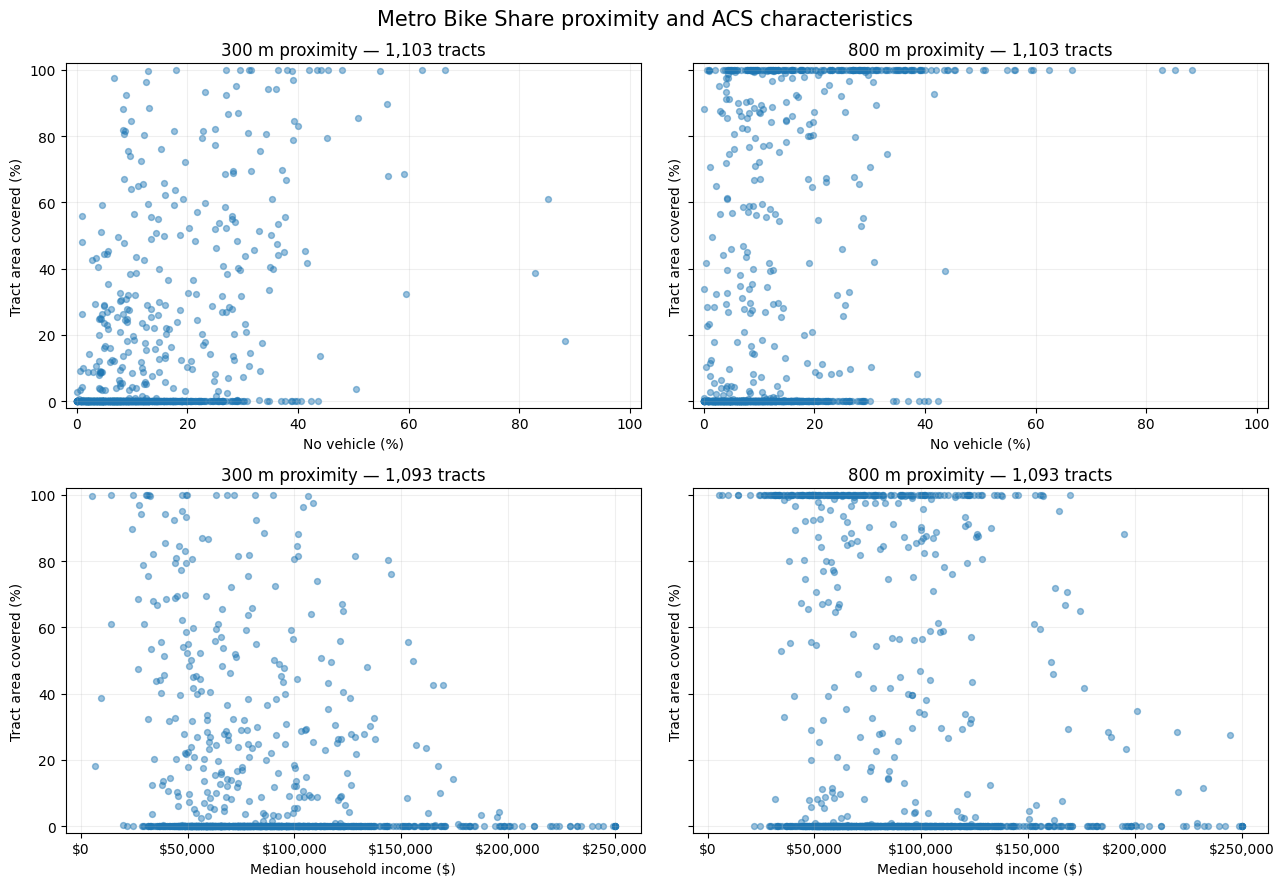

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)

for j, coverage_column in enumerate(coverage_columns):
    radius_m = [300, 800][j]

    for i, x_column in enumerate([
        "No vehicle (%)",
        "Median household income ($)"
    ]):
        plot_data = report[
            [x_column, coverage_column]
        ].dropna()

        ax = axes[i, j]

        ax.scatter(
            plot_data[x_column],
            plot_data[coverage_column],
            s=18,
            alpha=0.45
        )

        ax.set_title(
            f"{radius_m} m proximity — {len(plot_data):,} tracts"
        )
        ax.set_xlabel(x_column)
        ax.set_ylabel("Tract area covered (%)")
        ax.set_ylim(-2, 102)
        ax.grid(alpha=0.2)

        if i == 0:
            ax.set_xlim(-2, 102)
        else:
            ax.xaxis.set_major_formatter(
                StrMethodFormatter("${x:,.0f}")
            )

fig.suptitle(
    "Metro Bike Share proximity and ACS characteristics",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
close_column, broad_column = coverage_columns

no_vehicle_threshold = report["No vehicle (%)"].quantile(0.75)
coverage_threshold = 25.0  # Change this to explore other cutoffs

candidates = report.loc[
    report["No vehicle (%)"].ge(no_vehicle_threshold)
    & report[close_column].lt(coverage_threshold)
].copy()

# Sort by household count to show the scale of transportation need
candidates = candidates.sort_values(
    "Households without a vehicle",
    ascending=False
)

print(
    f"Screen: no-vehicle households ≥ {no_vehicle_threshold:.1f}% "
    f"and 300 m area coverage < {coverage_threshold:.0f}%"
)
print(f"Candidate tracts: {len(candidates):,}")

candidate_columns = [
    "Neighborhood", "Census tract", "GEOID",
    "Total households", "Households without a vehicle",
    "No vehicle (%)", "Median household income ($)",
    "Population", "Stations inside tract"
] + coverage_columns

display(
    candidates[candidate_columns].head(20).style.format({
        "Total households": "{:,.0f}",
        "Households without a vehicle": "{:,.0f}",
        "No vehicle (%)": "{:.1f}%",
        "Median household income ($)": "${:,.0f}",
        "Population": "{:,.0f}",
        **{column: "{:.1f}%" for column in coverage_columns}
    }, na_rep="Missing")
)

Screen: no-vehicle households ≥ 16.0% and 300 m area coverage < 25%
Candidate tracts: 177


,Neighborhood,Census tract,GEOID,Total households,Households without a vehicle,No vehicle (%),Median household income ($),Population,Stations inside tract,Tract area within 300m of a station (%),Tract area within 800m of a station (%)
893,Hyde Park,Tract 2349.02,06037234902,"2,101",891,42.4%,"$24,648","4,450",0,0.0%,0.0%
1644,Watts,Tract 2426.00,06037242600,"1,476",599,40.6%,"$21,595","4,749",0,0.0%,0.0%
1746,Hollywood,Tract 1909.01,06037190901,"1,278",558,43.7%,"$40,577","3,673",0,0.0%,39.2%
1961,Westlake,Tract 2083.02,06037208302,"1,774",539,30.4%,"$60,156","4,577",0,23.2%,100.0%
256,Baldwin Hills/Crenshaw,Tract 2361.01,06037236101,"1,325",528,39.8%,"$34,981","2,596",0,0.0%,0.0%
1117,San Pedro,Tract 2962.20,06037296220,"2,006",526,26.2%,"$46,288","3,924",0,0.0%,0.0%
1174,Vermont Square,Tract 2317.20,06037231720,"1,550",514,33.2%,"$45,417","5,078",0,9.1%,74.5%
621,Westlake,Tract 2091.05,06037209105,991,501,50.6%,"$33,234","2,995",0,3.7%,100.0%
1513,San Pedro,Tract 2966.00,06037296600,"2,130",497,23.3%,"$41,563","5,319",0,0.0%,0.0%
2259,Vermont Knolls,Tract 2382.00,06037238200,"2,205",490,22.2%,"$49,601","6,588",0,0.0%,0.0%


- 16% is an exploratory threshold, not an official definition of transportation need or underserved status.

Calculation:

no_vehicle_threshold = report["No vehicle (%)"].quantile(0.75)

- This selects roughly the highest quarter of tracts by the percentage of households without a vehicle. In our data, that threshold rounds to 16%.

- The 25% cutoff means less than one-quarter of a tract’s geographic area is within the chosen distance (300 m ) of a bike-share station, more than 75% of its area is outside those buffers. That makes it useful for an initial screen—but it doesn’t establish that the tract is underserved.

- Geographic coverage doesn’t tell us where residents live, so low coverage is a reason for further review, rather than proof that most residents lack access.

In [ ]:
import getpass

carto_key = getpass.getpass("Paste your CARTO basemap key: ")

map_candidates = folium.Map(
    location=[34.05, -118.25],
    zoom_start=10,
    name="Street map",
    tiles=(
        "https://basemaps.cartocdn.com/rastertiles/voyager/"
        "{z}/{x}/{y}.png?key=" + carto_key
    ),
    attr="© OpenStreetMap contributors, © CARTO",
    width="100%",
    height=650
)
folium.GeoJson(
    la_city.to_crs("EPSG:4326"),
    name="Los Angeles city boundary",
    style_function=lambda feature: {
        "color": "#333333",
        "weight": 2,
        "fillOpacity": 0
    }
).add_to(map_candidates)


# Add separate buffer layers
for radius_m, color in [(800, "#ffb347"), (300, "#52b788")]:
    buffer_shapes = gpd.GeoDataFrame(
        geometry=[buffers_by_radius[radius_m]],
        crs="EPSG:3310"
    ).to_crs("EPSG:4326")

    folium.GeoJson(
        buffer_shapes,
        name=f"{radius_m} m station buffers",
        show=(radius_m == 300),
        style_function=lambda feature, color=color: {
            "color": color,
            "weight": 1,
            "fillColor": color,
            "fillOpacity": 0.18
        }
    ).add_to(map_candidates)

# Add candidate tracts with hover information
if not candidates.empty:
    candidate_shapes = (
        tracts_in_city[["GEOID", "geometry"]]
        .merge(
            candidates[candidate_columns],
            on="GEOID",
            validate="one_to_one"
        )
        .to_crs("EPSG:4326")
    )

    tooltip_fields = [
        "Neighborhood", "Census tract", "No vehicle (%)"
    ] + coverage_columns

    for column in ["No vehicle (%)"] + coverage_columns:
        candidate_shapes[column] = candidate_shapes[column].round(1)

    folium.GeoJson(
        candidate_shapes[["geometry"] + tooltip_fields],
        name="Candidate tracts",
        style_function=lambda feature: {
            "color": "#7b2cbf",
            "weight": 2,
            "fillColor": "#7b2cbf",
            "fillOpacity": 0.25
        },
        tooltip=folium.GeoJsonTooltip(fields=tooltip_fields)
    ).add_to(map_candidates)

# Add station points
station_layer = folium.FeatureGroup(name="Active stations")

for _, row in station_points.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=3,
        color="blue",
        fill=True,
        fill_opacity=0.9,
        tooltip=str(row.get("Kiosk Name", "Station"))
    ).add_to(station_layer)

station_layer.add_to(map_candidates)

folium.LayerControl(collapsed=True).add_to(map_candidates)

bounds = la_city.to_crs("EPSG:4326").total_bounds
map_candidates.fit_bounds([
    [bounds[1], bounds[0]],
    [bounds[3], bounds[2]]
])

from IPython.display import HTML, display
from html import escape

map_html = escape(map_candidates.get_root().render(), quote=True)

display(HTML(
    f'<iframe srcdoc="{map_html}" '
    'style="width:100%; height:650px; border:none; display:block;">'
    '</iframe>'
))


Paste your CARTO basemap key: ··········


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [ ]:

map_candidates.save("la_bike_share_access.html")

from google.colab import files
files.download("la_bike_share_access.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
acs_by_tract = tracts_in_city.set_index("GEOID")

moe_fields = {
    "B08201_001M": "Total households MOE",
    "B08201_002M": "No-vehicle households MOE",
    "B19013_001M": "Income MOE ($)",
    "B01003_001M": "Population MOE"
}

for field, label in moe_fields.items():
    values = pd.to_numeric(acs_by_tract[field], errors="coerce")
    report[label] = report["GEOID"].map(values.where(values.ge(0)))

candidates = candidates.drop(
    columns=list(moe_fields.values()), errors="ignore"
).merge(
    report[["GEOID"] + list(moe_fields.values())],
    on="GEOID",
    how="left",
    validate="one_to_one"
)

display(
    candidates[
        ["Neighborhood", "GEOID",
         "Households without a vehicle",
         "No-vehicle households MOE",
         "Total households MOE",
         "Income MOE ($)", "Population MOE"]
    ].head(20).style.format({
        "Households without a vehicle": "{:,.0f}",
        **{
            label: "{:,.0f}"
            for label in moe_fields.values()
        }
    }, na_rep="Missing")
)

,Neighborhood,GEOID,Households without a vehicle,No-vehicle households MOE,Total households MOE,Income MOE ($),Population MOE
0,Hyde Park,06037234902,891,397,447,"14,763",668
1,Watts,06037242600,599,190,199,"10,748",808
2,Hollywood,06037190901,558,150,138,"11,774",455
3,Westlake,06037208302,539,203,235,"12,371",656
4,Baldwin Hills/Crenshaw,06037236101,528,248,230,"7,613",425
5,San Pedro,06037296220,526,251,181,"9,597",502
6,Vermont Square,06037231720,514,209,188,"24,319",803
7,Westlake,06037209105,501,205,209,"11,778",697
8,San Pedro,06037296600,497,403,355,"13,817",731
9,Vermont Knolls,06037238200,490,247,263,"18,572","1,113"


- Show how much uncertainty there is (Margin of Error) in the ACS estimates for the first 20 candidate tracts.
- ACS figures are survey estimates with sampling uncertainty; candidate tracts are identified for further assessment.”